# Task 4: Logistic Regression Classification

## Objective

The objective of this task is to build and evaluate a binary classification model using Logistic Regression.

In this task, we will:
- Load and explore the dataset
- Preprocess the data
- Split the data into training and testing sets
- Standardize the features
- Train a Logistic Regression model
- Evaluate the model using confusion matrix, precision, recall, and ROC-AUC
- Tune the classification threshold
- Understand the sigmoid function
- Interpret the model results

In [19]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


## 3. Load the Dataset

For this task, we use the Breast Cancer Wisconsin dataset available in Scikit-learn.

The dataset contains features computed from breast cancer diagnostic images.

The target variable represents two classes:
- 0: Malignant
- 1: Benign

In [20]:
# Load the Breast Cancer Wisconsin dataset

data = load_breast_cancer()

# Create DataFrame
X = pd.DataFrame(data.data, columns=data.feature_names)

# Create target variable
y = pd.Series(data.target, name="target")

print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

Dataset loaded successfully!
Number of samples: 569
Number of features: 30


## 4. Dataset Exploration

We inspect the dataset to understand its structure, feature values, missing values, and target class distribution.

In [21]:
# Display the first five rows

X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [22]:
# Check for missing values

print("Missing values in the dataset:")
print(X.isnull().sum().sum())

Missing values in the dataset:
0


In [23]:
# Display target class distribution

print("Target class distribution:")
print(y.value_counts())

print("\nTarget class names:")
print(dict(enumerate(data.target_names)))

Target class distribution:
target
1    357
0    212
Name: count, dtype: int64

Target class names:
{0: np.str_('malignant'), 1: np.str_('benign')}


In [24]:
# Statistical summary of numerical features

X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


## 5. Train-Test Split

The dataset is divided into training and testing sets.

- 80% of the data is used for training.
- 20% of the data is used for testing.
- `random_state=42` ensures reproducible results.
- `stratify=y` maintains the class distribution in both sets.

In [25]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

Training samples: 455
Testing samples: 114
Training features: 30
Testing features: 30


## 6. Feature Standardization

Feature standardization is performed using `StandardScaler`.

Standardization helps Logistic Regression perform better when features have different scales.

The scaler is fitted only on the training data and then used to transform both training and testing data.

In [26]:
# Standardize the features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature standardization completed successfully!")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature standardization completed successfully!
Scaled training data shape: (455, 30)
Scaled testing data shape: (114, 30)


## 7. Train the Logistic Regression Model

Logistic Regression is used to perform binary classification.

The model learns the relationship between the input features and the target classes.

The trained model will be used to predict whether a sample belongs to class 0 or class 1.

In [27]:
# Create the Logistic Regression model

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


## 8. Predictions

After training the Logistic Regression model, predictions are made on the test dataset.

We obtain:
- Predicted class labels using `predict()`
- Prediction probabilities using `predict_proba()`

In [28]:
# Make predictions on the test data

y_pred = logistic_model.predict(X_test_scaled)

# Get probability of class 1
y_pred_proba = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")
print("First 10 predicted classes:")
print(y_pred[:10])

print("\nFirst 10 predicted probabilities:")
print(y_pred_proba[:10])

Predictions generated successfully!
First 10 predicted classes:
[0 1 0 1 0 1 1 0 0 0]

First 10 predicted probabilities:
[5.88824186e-08 9.99988665e-01 6.41082462e-03 5.33508537e-01
 6.52500097e-10 9.92160398e-01 9.99982825e-01 5.63527494e-07
 5.43163692e-05 8.04184941e-11]


## 9. Model Evaluation

The Logistic Regression model is evaluated using accuracy, precision, recall, and ROC-AUC.

- **Accuracy:** Measures the overall percentage of correct predictions.
- **Precision:** Measures how many predicted positive cases are actually positive.
- **Recall:** Measures how many actual positive cases are correctly identified.
- **ROC-AUC:** Measures the model's ability to distinguish between the two classes across different classification thresholds.

In [29]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("Model Evaluation Metrics")
print("------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Model Evaluation Metrics
------------------------
Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
ROC-AUC  : 0.9954


## 10. Classification Report

The classification report provides precision, recall, F1-score, and support for each class.

In [30]:
# Display the classification report

print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



# Display the classification report

print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

In [31]:
# Calculate the confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[41  1]
 [ 1 71]]


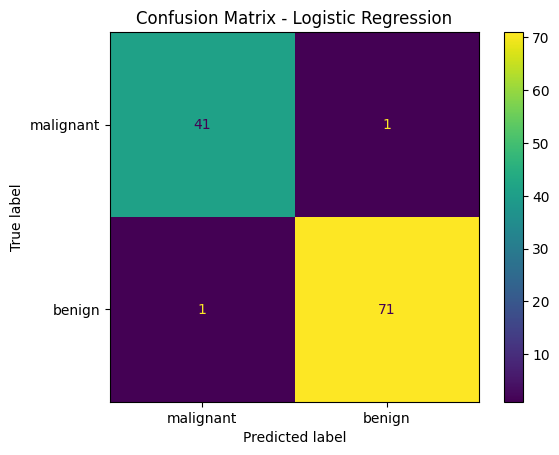

In [32]:
# Plot the confusion matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot()

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

## 12. ROC Curve

The ROC curve shows the relationship between the True Positive Rate and False Positive Rate at different classification thresholds.

The Area Under the Curve (ROC-AUC) represents how well the model can distinguish between the two classes.

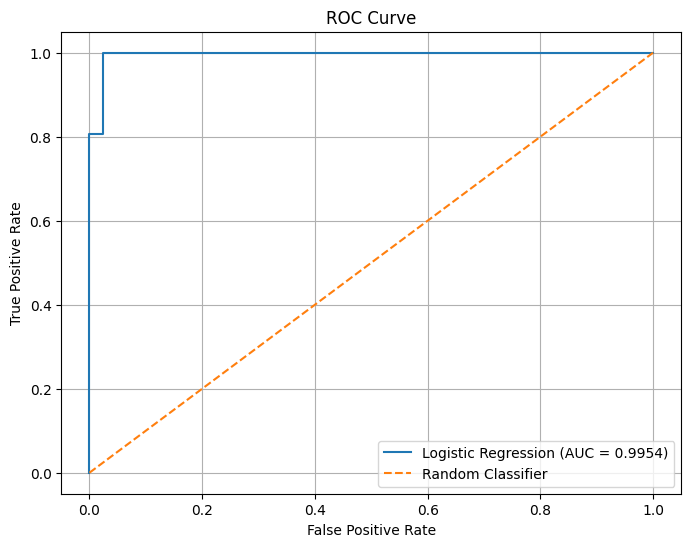

In [33]:
# Calculate ROC curve

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# Plot ROC curve

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

## 13. Threshold Tuning

Logistic Regression usually uses a threshold of 0.50 to convert predicted probabilities into class labels.

In this section, we change the threshold to 0.40 and observe how precision and recall change.

A lower threshold makes the model more likely to classify an observation as the positive class.

In [34]:
# Tune the classification threshold

threshold = 0.40

y_pred_threshold = (y_pred_proba >= threshold).astype(int)

threshold_precision = precision_score(
    y_test,
    y_pred_threshold
)

threshold_recall = recall_score(
    y_test,
    y_pred_threshold
)

threshold_accuracy = accuracy_score(
    y_test,
    y_pred_threshold
)

print(f"Threshold: {threshold:.2f}")
print(f"Accuracy : {threshold_accuracy:.4f}")
print(f"Precision: {threshold_precision:.4f}")
print(f"Recall   : {threshold_recall:.4f}")

Threshold: 0.40
Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861


In [35]:
# Compare the default and tuned thresholds

default_precision = precision_score(y_test, y_pred)
default_recall = recall_score(y_test, y_pred)

print("Threshold Comparison")
print("--------------------")

print("\nThreshold = 0.50")
print(f"Precision: {default_precision:.4f}")
print(f"Recall   : {default_recall:.4f}")

print("\nThreshold = 0.40")
print(f"Precision: {threshold_precision:.4f}")
print(f"Recall   : {threshold_recall:.4f}")

Threshold Comparison
--------------------

Threshold = 0.50
Precision: 0.9861
Recall   : 0.9861

Threshold = 0.40
Precision: 0.9861
Recall   : 0.9861


## 14. Sigmoid Function

Logistic Regression uses the sigmoid function to convert the model's output into a probability between 0 and 1.

The sigmoid function has an S-shaped curve.

Its output can be interpreted as the probability of belonging to the positive class.

For binary classification:
- A probability close to 0 indicates class 0.
- A probability close to 1 indicates class 1.
- A threshold such as 0.50 can be used to convert probability into a class prediction.

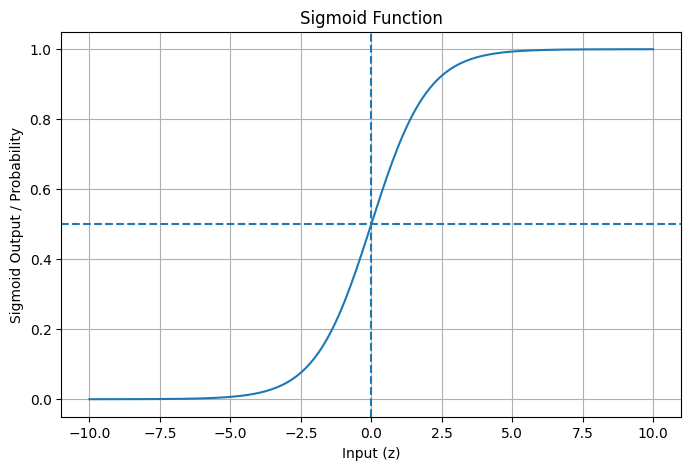

In [36]:
# Define the sigmoid function

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Generate values for the graph
z = np.linspace(-10, 10, 200)
sigmoid_values = sigmoid(z)

# Plot sigmoid function
plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid_values)

plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")

plt.xlabel("Input (z)")
plt.ylabel("Sigmoid Output / Probability")
plt.title("Sigmoid Function")

plt.grid()
plt.show()

## 15. Observations

The following observations were made from the Logistic Regression model:

1. The dataset was successfully divided into training and testing sets using an 80:20 ratio.

2. Feature standardization was applied using StandardScaler because the input features have different scales.

3. Logistic Regression successfully classified the two target classes.

4. Accuracy, precision, recall, and ROC-AUC were used to evaluate model performance.

5. The confusion matrix shows the number of correct and incorrect predictions for both classes.

6. The ROC curve helps visualize the model's ability to distinguish between the two classes.

7. Changing the classification threshold from 0.50 to 0.40 changes the balance between precision and recall.

8. The sigmoid function converts the model output into a probability between 0 and 1.

## 16. Conclusion

In this task, a Logistic Regression model was implemented for binary classification using the Breast Cancer Wisconsin dataset.

The dataset was explored, split into training and testing sets, and the features were standardized before model training.

The model was evaluated using accuracy, precision, recall, confusion matrix, and ROC-AUC.

Threshold tuning demonstrated that changing the classification threshold can affect precision and recall.

Overall, this task provided practical understanding of Logistic Regression, probability-based classification, model evaluation, threshold selection, and the sigmoid function.

## 17. Interview Questions and Answers

### 1. How does Logistic Regression differ from Linear Regression?

Linear Regression predicts continuous numerical values, whereas Logistic Regression is mainly used for classification and predicts probabilities between 0 and 1.

### 2. What is the sigmoid function?

The sigmoid function converts a real-valued input into a value between 0 and 1. This output can be interpreted as a probability.

### 3. What is the difference between precision and recall?

Precision measures how many predicted positive cases are actually positive.

Recall measures how many actual positive cases are correctly identified.

### 4. What is an ROC-AUC curve?

The ROC curve shows the relationship between the True Positive Rate and False Positive Rate at different classification thresholds. AUC summarizes the model's ability to distinguish between classes.

### 5. What is a confusion matrix?

A confusion matrix summarizes classification predictions using True Positive, True Negative, False Positive, and False Negative values.

### 6. What happens if classes are imbalanced?

A model may become biased toward the majority class. Accuracy alone may then be misleading, so metrics such as precision, recall, F1-score, and ROC-AUC should also be considered.

### 7. How do you choose a classification threshold?

The threshold can be selected according to the application and the desired balance between precision and recall. The default threshold is commonly 0.50, but it can be adjusted when needed.

### 8. Can Logistic Regression be used for multi-class problems?

Yes. Logistic Regression can be extended to multi-class classification using approaches such as One-vs-Rest or multinomial classification.